# シミュレーションの試作：M0・M1 からセッションを生成する（監査サンプル）

**試作であり、評価ではない。** 監査サンプル（KT4、各32人）で M0（全体頻度）と M1（全体一次Markov）を推定し、同じデータと比べる（学習と比較が同じデータ）。
CLAUDE.md の「再現性：生成した系列のカテゴリ頻度・セッション長・終了率を実データと比較する」の流れを、小さいデータで一通り動かすことが目的。

- カテゴリ：KT4 用ノートブックの `CATEGORY_MAP`（問題・解説・講義・補助操作。pay は対象外）。予測対象には「終了」を加えた5クラス（2026-10-22 決定）
- セッション：60分区切り。セッションの最後の行の次を「終了」とする。各学習者のデータ末尾は対象外（D4）
- フェーズ1の前処理パイプライン（セクション5）は未確定。ここでの前処理は試作用で、本番の前処理ではない

## 0. 設定とデータ

In [1]:
from pathlib import Path
import bisect, json, platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
SEED = 0
SESSION_GAP_MIN = 60
N_SIM_SESSIONS = 20_000
MAX_SESSION_LEN = 100_000      # 生成の打ち切り（終了の確率は正なので、通常は届かない）
CATEGORY_MAP = {               # phase1_ednet_audit_KT4.ipynb セクション2と同じ
    ("enter", "b"): "solve", ("respond", "q"): "solve", ("submit", "b"): "solve",
    ("enter", "e"): "review", ("quit", "e"): "review",
    ("enter", "l"): "lecture", ("quit", "l"): "lecture", ("play_video", "l"): "lecture", ("pause_video", "l"): "lecture",
    ("play_audio", "b"): "aux", ("pause_audio", "b"): "aux", ("erase_choice", "q"): "aux", ("undo_erase_choice", "q"): "aux",
    ("pay", "p"): None,
}
STATES = ["solve", "review", "lecture", "aux"]
OUTCOMES = STATES + ["end"]

C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#1a1a19", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True})
print("Python", platform.python_version(), "/ pandas", pd.__version__, "/ numpy", np.__version__)

users3 = sorted(json.loads((ROOT / "data/audit/KT3/manifest.json").read_text(encoding="utf-8"))["audit_users"])
users4 = sorted(json.loads((ROOT / "data/audit/KT4/manifest.json").read_text(encoding="utf-8"))["audit_users"])
PATHS = {"KT4 audit (SEED=0)": [ROOT / "data/audit/KT4" / f"{u}.csv" for u in users4],
         "KT4 same 32": [ROOT / "data/raw/KT4" / f"{u}.csv" for u in users3]}   # KT3 監査32人の同名ファイルだけを開く

Python 3.11.9 / pandas 3.0.6 / numpy 2.4.6


## 1. 前処理（試作用）
カテゴリを付け、対象外（pay）の行を落としてから、セッションを区切る（KT4 用ノートブックのセル22と同じ順）。
各行の予測対象 `target` は、同じセッションの次の行のカテゴリ。セッションの最後の行なら `end`。各学習者の最後の行は `NaN`（対象外）。

In [2]:
def preprocess(paths):
    d = pd.concat([pd.read_csv(p).assign(user_id=p.stem) for p in paths], ignore_index=True)
    d = d.sort_values(["user_id", "timestamp"], kind="stable")
    d["category"] = [CATEGORY_MAP.get((a, i), "UNMAPPED") for a, i in zip(d["action_type"], d["item_id"].astype(str).str[0])]
    assert not d["category"].eq("UNMAPPED").any()
    d = d[d["category"].notna()].reset_index(drop=True)
    gap = d.groupby("user_id")["timestamp"].diff() / 60000
    d["session_id"] = (gap.isna() | (gap > SESSION_GAP_MIN)).groupby(d["user_id"]).cumsum()
    nxt_cat = d.groupby("user_id")["category"].shift(-1)
    nxt_sid = d.groupby("user_id")["session_id"].shift(-1)
    d["target"] = nxt_cat.where(nxt_sid.eq(d["session_id"]), "end")
    d.loc[nxt_cat.isna(), "target"] = np.nan                      # データ末尾（D4）
    last = d.groupby("user_id")["session_id"].transform("max")
    d["censored_session"] = d["session_id"].eq(last)              # データ末尾で終わるセッション
    return d

DATA = {name: preprocess(p) for name, p in PATHS.items()}
pd.DataFrame({name: {"行": len(d), "学習者": d["user_id"].nunique(),
                     "セッション": d.groupby(["user_id", "session_id"]).ngroups,
                     "完了したセッション": d[~d["censored_session"]].groupby(["user_id", "session_id"]).ngroups,
                     "予測対象のある行": int(d["target"].notna().sum())} for name, d in DATA.items()})

,KT4 audit (SEED=0),KT4 same 32
行,6521,25873
学習者,32,32
セッション,73,218
完了したセッション,41,186
予測対象のある行,6489,25841


## 2. M0・M1 の推定とセッションの生成
- 開始：各セッションの最初のカテゴリの経験分布（M0・M1 共通）
- M0：次のカテゴリ（終了を含む5クラス）の全体頻度。直前の状態によらない
- M1：直前のカテゴリ（4状態）ごとの、次のカテゴリ（5クラス）の経験分布
- 生成：開始カテゴリを引き、`end` が出るまで次のカテゴリを引き続ける。セッション長は行動の数（開始の行を含む）

In [3]:
def fit(d):
    t = d.dropna(subset=["target"])
    start = d.groupby(["user_id", "session_id"])["category"].first().value_counts(normalize=True).reindex(STATES, fill_value=0)
    m0 = t["target"].value_counts(normalize=True).reindex(OUTCOMES, fill_value=0)
    m1 = pd.crosstab(t["category"], t["target"], normalize="index").reindex(index=STATES, columns=OUTCOMES, fill_value=0)
    return start, m0, m1

def simulate(start, step_probs, n, rng):
    """step_probs(state) -> OUTCOMES の確率。セッションごとに (カテゴリの列) を返す。"""
    cum_start = np.cumsum(start.to_numpy()).tolist()
    cum = {s: np.cumsum(step_probs(s)).tolist() for s in STATES}
    draw = lambda c: min(bisect.bisect_right(c, rng.random()), len(c) - 1)
    sessions = []
    for _ in range(n):
        s = STATES[draw(cum_start)]
        seq = [s]
        while len(seq) < MAX_SESSION_LEN:
            nxt = OUTCOMES[draw(cum[s])]
            if nxt == "end":
                break
            seq.append(nxt); s = nxt
        sessions.append(seq)
    return sessions

FITS, SIMS = {}, {}
rng = np.random.default_rng(SEED)
for name, d in DATA.items():
    start, m0, m1 = fit(d)
    FITS[name] = (start, m0, m1)
    SIMS[name] = {"M0": simulate(start, lambda s: m0.to_numpy(), N_SIM_SESSIONS, rng),
                  "M1": simulate(start, lambda s: m1.loc[s].to_numpy(), N_SIM_SESSIONS, rng)}
display(pd.DataFrame({name: f[1] for name, f in FITS.items()}).T.round(4).rename_axis("M0：次のカテゴリの全体頻度"))
for name, f in FITS.items():
    display(f[2].round(3).rename_axis(f"M1（{name}）：直前→次"))

target,solve,review,lecture,aux,end
M0：次のカテゴリの全体頻度,,,,,
KT4 audit (SEED=0),0.5486,0.2620,0.0354,0.1476,0.0063
KT4 same 32,0.3470,0.1894,0.0038,0.4526,0.0072


target,solve,review,lecture,aux,end
M1（KT4 audit (SEED=0)）：直前→次,,,,,
solve,0.649,0.221,0.000,0.128,0.003
review,0.444,0.500,0.008,0.032,0.016
lecture,0.043,0.000,0.939,0.000,0.017
aux,0.480,0.057,0.000,0.462,0.000


target,solve,review,lecture,aux,end
M1（KT4 same 32）：直前→次,,,,,
solve,0.517,0.249,0.000,0.232,0.001
review,0.431,0.378,0.002,0.154,0.035
lecture,0.112,0.000,0.888,0.000,0.000
aux,0.181,0.065,0.000,0.754,0.000


## 3. 実データとの比較

In [4]:
def real_lengths(d, completed_only=True):
    x = d[~d["censored_session"]] if completed_only else d
    return x.groupby(["user_id", "session_id"]).size().to_numpy()

def length_summary(L):
    L = np.asarray(L)
    return {"セッション数": len(L), "平均": L.mean(), "中央値": np.median(L), "90%点": np.quantile(L, 0.9),
            "最大": L.max(), "長さ1の割合": (L == 1).mean()}

rows, freq = [], {}
for name, d in DATA.items():
    t = d.dropna(subset=["target"])
    real_c = real_lengths(d)
    rows.append({"データ": name, "系列": "実データ（完了したセッション）", **length_summary(real_c),
                 "終了率（行動あたり）": t["target"].eq("end").mean()})
    rows.append({"データ": name, "系列": "実データ（打ち切りを含む全セッション）", **length_summary(real_lengths(d, False)),
                 "終了率（行動あたり）": np.nan})
    freq[(name, "real")] = d["category"].value_counts(normalize=True).reindex(STATES, fill_value=0)
    for model, sess in SIMS[name].items():
        L = np.array([len(s) for s in sess])
        rows.append({"データ": name, "系列": model, **length_summary(L), "終了率（行動あたり）": len(L) / L.sum()})
        freq[(name, model)] = pd.Series(np.concatenate(sess)).value_counts(normalize=True).reindex(STATES, fill_value=0)
COMPARE = pd.DataFrame(rows).set_index(["データ", "系列"])
display(COMPARE.round(3))
FREQ = pd.DataFrame(freq).T
FREQ.index.names = ["データ", "系列"]
FREQ.round(3)

セッション数       平均    中央値   90%点    最大  \
データ                系列                                                         
KT4 audit (SEED=0) 実データ（完了したセッション）          41  111.951   74.0  248.0   533   
                   実データ（打ち切りを含む全セッション）      73   89.329   51.0  231.4   533   
                   M0                    20000  158.941  109.0  366.0  1476   
                   M1                    20000  159.522  112.0  365.0  1882   
KT4 same 32        実データ（完了したセッション）         186  129.355  105.5  268.0   611   
                   実データ（打ち切りを含む全セッション）     218  118.683   83.0  252.5   745   
                   M0                    20000  140.031   98.0  322.0  1391   
                   M1                    20000  138.308   96.0  320.0  1410   

                                        長さ1の割合  終了率（行動あたり）  
データ                系列                                       
KT4 audit (SEED=0) 実データ（完了したセッション）       0.000       0.006  
                   実データ（打ち切りを含む全セッション）   0.000         NaN  
                   M0                    0.007       0.006  
                   M1                    0.005       0.006  
KT4 same 32        実データ（完了したセッション）       0.000       0.007  
                   実データ（打ち切りを含む全セッション）   0.000         NaN  
                   M0                    0.006       0.007  
                   M1                    0.008       0.007

solve  review  lecture    aux
データ                系列                                 
KT4 audit (SEED=0) real  0.556   0.262    0.035  0.147
                   M0    0.554   0.263    0.035  0.148
                   M1    0.554   0.262    0.036  0.147
KT4 same 32        real  0.353   0.191    0.004  0.452
                   M0    0.353   0.191    0.004  0.453
                   M1    0.353   0.192    0.004  0.451

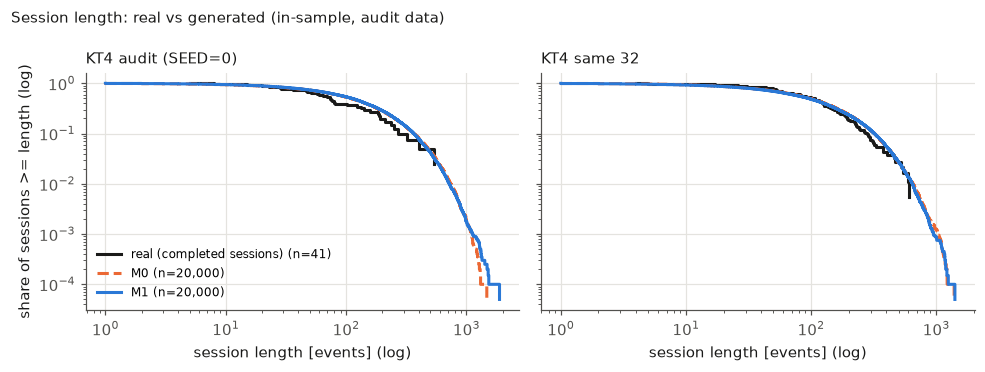

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, (name, d) in zip(axes, DATA.items()):
    for label, L, color, style in [("real (completed sessions)", real_lengths(d), INK, "-"),
                                   ("M0", [len(s) for s in SIMS[name]["M0"]], C2, "--"),
                                   ("M1", [len(s) for s in SIMS[name]["M1"]], C1, "-")]:
        x = np.sort(np.asarray(L))
        ax.step(x, 1 - np.arange(len(x)) / len(x), where="post", color=color, linestyle=style, linewidth=2,
                label=f"{label} (n={len(x):,})")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(name, loc="left", fontsize=10, color=INK)
    ax.set_xlabel("session length [events] (log)")
axes[0].set_ylabel("share of sessions >= length (log)")
axes[0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle("Session length: real vs generated (in-sample, audit data)", x=0.01, ha="left", fontsize=10, color=INK)
plt.tight_layout(); plt.show()

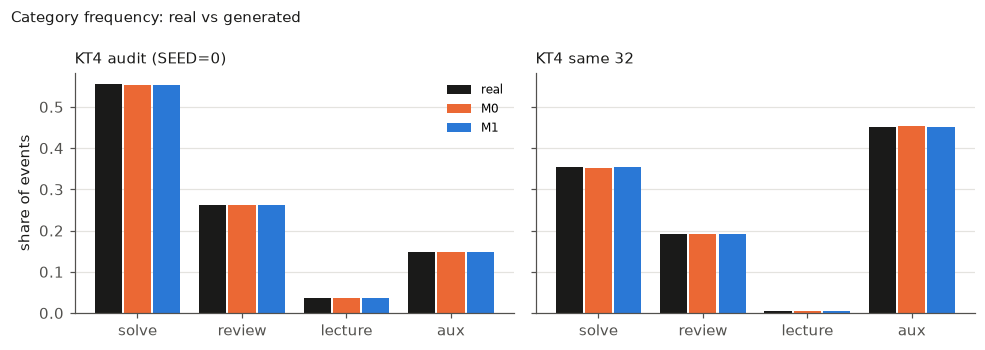

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, name in zip(axes, DATA):
    x = np.arange(len(STATES)); w = 0.26
    for i, (series, color) in enumerate([("real", INK), ("M0", C2), ("M1", C1)]):
        v = FREQ.loc[(name, series)].to_numpy()
        ax.bar(x + (i - 1) * (w + 0.02), v, width=w, color=color, label=series)
    ax.set_xticks(x, STATES)
    ax.set_title(name, loc="left", fontsize=10, color=INK)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("share of events")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Category frequency: real vs generated", x=0.01, ha="left", fontsize=10, color=INK)
plt.tight_layout(); plt.show()

## 4. 読むときの注意
- 学習と比較が同じデータ（in-sample）。M1 の終了率やカテゴリ頻度が実データに近いのは、推定の仕組み上ほぼ当然で、モデルの良さの証拠ではない。
- 実データの「完了したセッション」は、各学習者の最後のセッション（データ末尾で打ち切り）を除いたもの。学習者の多くはセッションが1つだけなので、件数が少ない。
- M0・M1 は学習者の違いを持たない。学習者別（M2）・階層（M3）は、フェーズ1の前処理を固めてから。
- 補助操作の多くは画面の流れでほぼ決まる遷移（play→pause など）で、M1 はそれもそのまま再現する。